In [1]:
!pip install -q ultralytics
!pip install mediapipe
import ultralytics; ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 5642.5/8156.9 GB disk)


In [2]:
%%writefile /kaggle/working/generate_yolo_dataset.py
"""
Synthetic eye-patch data generator -> YOLO-ready datasets (amblyopia / lazy eye project).

For every face image in INPUT_DIR it creates a PAIR:
    * the original face            (no patch)
    * the same face + ONE eye covered by a random patch

and saves them in two ready-to-train layouts:

  1) DETECTION  (YOLO detect)   ->  /kaggle/working/yolo_det
        input = the WHOLE face image, the model finds the eyes and says which one is covered.
        classes: 0 = eye_normal (uncovered eye) , 1 = eye_patched (eye under the patch)
        images/{train,val,test}/<name>_clean.jpg -> 2 boxes, both class 0   (normal face)
        images/{train,val,test}/<name>_patch.jpg -> 2 boxes: class 1 (patch box) + class 0 (the other eye)
        labels/{train,val,test}/<name>_*.txt      ("cls cx cy w h" normalized)
        data.yaml
  2) CLASSIFICATION (YOLO classify) -> /kaggle/working/yolo_cls
        {train,val,test}/{no_patch,with_patch}/<name>.jpg

Both images of a pair always go to the SAME split (no leakage between train/val/test).
Also writes meta.csv (split, style, covered eye, bbox) in OUTPUT_DIR.

Face + eye location comes from the MediaPipe Tasks API (FaceLandmarker).
Patch types: plain, skin (adhesive), pattern, fabric (stitched), pirate (+straps), velcro (+wide bands)
"""

import csv
import os
import random
import shutil
import urllib.request
from pathlib import Path

import cv2
import numpy as np

# ----------------------------- settings -----------------------------
INPUT_DIR = "/kaggle/input/datasets/ashwingupta3012/human-faces/Humans"   # searched recursively
OUTPUT_DIR = "/kaggle/working"
DET_DIR = f"{OUTPUT_DIR}/yolo_det"
CLS_DIR = f"{OUTPUT_DIR}/yolo_cls"
META_CSV = f"{OUTPUT_DIR}/meta.csv"
MODEL_PATH = "/kaggle/working/face_landmarker.task"   # downloaded automatically if missing
MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
             "face_landmarker/float16/1/face_landmarker.task")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

CLASS_NAMES = ["eye_normal", "eye_patched"]   # detection classes: 0 = uncovered eye, 1 = eye under a patch
CLS_NORMAL, CLS_PATCHED = 0, 1
# box around an uncovered eye (built from the landmarks): width = eye width * EYE_BOX_W,
# height = max(eye height * EYE_BOX_H, width * EYE_BOX_MIN_ASPECT)
EYE_BOX_W = 1.5
EYE_BOX_H = 2.0
EYE_BOX_MIN_ASPECT = 0.6
SPLITS = {"train": 0.8, "val": 0.1, "test": 0.1}
MAX_IMAGES = None                   # e.g. 2000 for a quick test run, None = all
MAX_SIDE = 640                      # resize so the longest side <= this (None = keep original size)
MIN_BOX_PX = 8                      # skip if the patch box is smaller than this (pixels)

SEED = 42                           # None = different result every run
SKIP_IF_OTHER_EYE_CLOSED = True     # the uncovered eye must be open
BLINK_THRESHOLD = 0.5
JPEG_QUALITY = 95

STYLES = ["plain", "skin", "pattern", "fabric", "pirate", "velcro"]
STYLE_WEIGHTS = [3, 3, 3, 2, 2, 1]

# MediaPipe face mesh indices ("right" = the subject's right eye = left side of the image)
EYES = {
    "right": dict(ids=[33, 7, 163, 144, 145, 153, 154, 155, 133, 173, 157, 158, 159, 160, 161, 246],
                  outer=33, inner=133, ear=234, temple_top=21, blink="eyeBlinkRight"),
    "left": dict(ids=[362, 382, 381, 380, 374, 373, 390, 249, 263, 466, 388, 387, 386, 385, 384, 398],
                 outer=263, inner=362, ear=454, temple_top=251, blink="eyeBlinkLeft"),
}
FOREHEAD = 10

SKIN_TONES = [(180, 200, 235), (170, 195, 232), (140, 175, 215), (100, 140, 190),
              (85, 125, 175), (65, 95, 140), (195, 215, 240)]  # BGR


# ----------------------------- colors -----------------------------
def jitter(c, rng, amount):
    return tuple(int(np.clip(v + rng.uniform(-amount, amount), 0, 255)) for v in c)


def rand_vivid(rng):
    hsv = np.uint8([[[rng.uniform(0, 179), rng.uniform(110, 255), rng.uniform(140, 255)]]])
    return tuple(int(x) for x in cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)[0, 0])


def rand_dark(rng):
    g = rng.randint(10, 50)
    return (g + rng.randint(0, 8), g, g)


def rand_skin(rng):
    return jitter(rng.choice(SKIN_TONES), rng, 16)


def luminance(c):
    return 0.114 * c[0] + 0.587 * c[1] + 0.299 * c[2]


def contrast_color(c, rng):
    if luminance(c) > 135:
        return rng.choice([rand_dark(rng), jitter((90, 60, 40), rng, 40), rand_vivid(rng)])
    return rng.choice([(245, 245, 245), (225, 235, 250), rand_vivid(rng)])


# ----------------------------- shapes -----------------------------
def shape_polygon(W, H, rng, pad=3):
    """Egg / oval / rounded-square outline, a bit wider at the bottom like real patches."""
    k = rng.uniform(0.0, 0.25)
    p = rng.uniform(2.0, 3.2)
    t = np.linspace(0, 2 * np.pi, 200, endpoint=False)
    c, s = np.cos(t), np.sin(t)
    x = np.sign(c) * np.abs(c) ** (2 / p)
    y = np.sign(s) * np.abs(s) ** (2 / p)
    x = x * (1 + k * y)
    a = (W / 2 - pad) / (1 + k)
    b = H / 2 - pad
    return np.stack([W / 2 + a * x, H / 2 + b * y], 1)


def heart(cx, cy, r):
    t = np.linspace(0, 2 * np.pi, 40)
    x = 16 * np.sin(t) ** 3
    y = -(13 * np.cos(t) - 5 * np.cos(2 * t) - 2 * np.cos(3 * t) - np.cos(4 * t))
    return np.round(np.stack([cx + x * r / 17, cy + y * r / 17], 1)).astype(np.int32)


def star(cx, cy, r):
    pts = []
    for i in range(10):
        ang = -np.pi / 2 + i * np.pi / 5
        rad = r if i % 2 == 0 else r * 0.45
        pts.append([cx + rad * np.cos(ang), cy + rad * np.sin(ang)])
    return np.round(np.array(pts)).astype(np.int32)


def draw_dashed(img, poly, color, thickness, on=3, off=2):
    n = len(poly)
    i = 0
    while i < n:
        seg = [poly[(i + j) % n] for j in range(on + 1)]
        cv2.polylines(img, [np.round(seg).astype(np.int32)], False, color, thickness, cv2.LINE_AA)
        i += on + off


# ----------------------------- patterns -----------------------------
def apply_pattern(img, base, rng):
    H, W = img.shape[:2]
    m = min(W, H)
    col = contrast_color(base, rng)
    kind = rng.choice(["stripes", "dots", "checker", "stars", "hearts", "circles", "zigzag"])
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)

    if kind in ("stripes", "checker"):
        period = rng.uniform(0.10, 0.25) * m
        if kind == "stripes":
            ang = rng.choice([0, np.pi / 2, np.pi / 4, -np.pi / 4])
            proj = xx * np.cos(ang) + yy * np.sin(ang)
            band = (np.floor(proj / period) % 2) == 0
        else:
            band = ((np.floor(xx / period) + np.floor(yy / period)) % 2) == 0
        img[band] = col
    elif kind == "zigzag":
        period = rng.uniform(0.12, 0.25) * m
        for y0 in np.arange(-period, H + period, period * 1.6):
            pts = [[x, y0 + (period * 0.5 if (i % 2) else 0)]
                   for i, x in enumerate(np.arange(-period, W + period, period * 0.5))]
            cv2.polylines(img, [np.round(pts).astype(np.int32)], False, col,
                          max(1, int(period * 0.25)), cv2.LINE_AA)
    else:
        step = rng.uniform(0.18, 0.32) * m
        r = step * rng.uniform(0.25, 0.4)
        row = 0
        for y0 in np.arange(step / 2, H, step):
            off = (step / 2) if row % 2 else 0
            for x0 in np.arange(step / 2 + off - step, W + step, step):
                if kind == "dots":
                    cv2.circle(img, (int(x0), int(y0)), max(1, int(r)), col, -1, cv2.LINE_AA)
                elif kind == "circles":
                    cv2.circle(img, (int(x0), int(y0)), max(2, int(r * 1.3)), col,
                               max(1, int(r * 0.35)), cv2.LINE_AA)
                elif kind == "stars":
                    cv2.fillPoly(img, [star(x0, y0, r * 1.5)], col, cv2.LINE_AA)
                else:
                    cv2.fillPoly(img, [heart(x0, y0, r * 1.6)], col, cv2.LINE_AA)
            row += 1


# ----------------------------- per-image color variation -----------------------------
def random_tint(patch, color, style, rng):
    """Random hue / saturation / brightness change so every image gets different shades."""
    dh = rng.uniform(-6, 6) if style == "skin" else rng.uniform(-90, 90)   # OpenCV hue range is 0-179
    ds = rng.uniform(0.6, 1.4)
    dv = rng.uniform(0.75, 1.25)

    def shift(arr):
        hsv = cv2.cvtColor(arr, cv2.COLOR_BGR2HSV).astype(np.float32)
        hsv[..., 0] = (hsv[..., 0] + dh) % 180
        hsv[..., 1] = np.clip(hsv[..., 1] * ds, 0, 255)
        hsv[..., 2] = np.clip(hsv[..., 2] * dv, 0, 255)
        return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    new_color = tuple(int(x) for x in shift(np.uint8([[color]]))[0, 0])
    return shift(patch), new_color


# ----------------------------- patch texture -----------------------------
def build_patch(W, H, style, rng):
    """Returns (bgr uint8 HxWx3, alpha float32 HxW, main_color)."""
    poly = shape_polygon(W, H, rng)
    mask = np.zeros((H, W), np.uint8)
    cv2.fillPoly(mask, [np.round(poly).astype(np.int32)], 255)
    alpha = (cv2.GaussianBlur(mask, (0, 0), 0.8) / 255.0).astype(np.float32)
    m = min(W, H)
    center = np.array([W / 2, H / 2])

    # --- base color
    if style == "skin":
        color = rand_skin(rng)
    elif style in ("pirate", "velcro"):
        color = rng.choice([rand_dark(rng), rand_dark(rng), jitter((60, 70, 90), rng, 20), rand_vivid(rng)])
    elif style == "fabric":
        color = rng.choice([rand_vivid(rng), rand_dark(rng), rand_skin(rng)])
    elif style == "pattern":
        color = rng.choice([rand_vivid(rng), rand_skin(rng), (240, 240, 240), rand_dark(rng)])
    else:  # plain
        color = rng.choice([rand_skin(rng), rand_vivid(rng), rand_dark(rng), (235, 235, 235)])

    img = np.empty((H, W, 3), np.uint8)
    img[:] = color
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)

    if style == "pattern":
        apply_pattern(img, color, rng)

    f = img.astype(np.float32)

    # --- soft linear gradient (lighting / color variation)
    ang = rng.uniform(0, 2 * np.pi)
    g = ((xx / W - 0.5) * np.cos(ang) + (yy / H - 0.5) * np.sin(ang))
    f *= (1 + rng.uniform(-0.3, 0.3) * g)[..., None]

    # --- adhesive look: lighter outer rim + darker inner pad
    if style == "skin" and rng.random() < 0.6:
        inner = np.zeros((H, W), np.uint8)
        cv2.fillPoly(inner, [np.round(center + (poly - center) * 0.62).astype(np.int32)], 255)
        inner = cv2.GaussianBlur(inner, (0, 0), m * 0.02).astype(np.float32)[..., None] / 255.0
        f = f * (1 - inner * 0.9) + np.array(jitter(color, rng, 6)) * 0.88 * inner * 0.9
        f = f * (1 - 0.12 * (1 - inner)) + 255 * 0.12 * (1 - inner)

    # --- texture: non-woven weave or fine noise
    if style in ("fabric", "velcro", "pirate") and rng.random() < 0.7:
        gsz = max(2, int(m / rng.uniform(25, 50)))
        weave = ((np.floor(xx / gsz) + np.floor(yy / gsz)) % 2).astype(np.float32)
        f *= (1 - 0.07 * weave)[..., None]
    sigma = rng.uniform(2, 10) if style in ("skin", "fabric", "plain") else rng.uniform(0, 4)
    noise = cv2.GaussianBlur(np.random.normal(0, sigma, (H, W)).astype(np.float32), (0, 0), 0.6)
    f += noise[..., None]

    # --- 3D bulge: highlight + darker edges (strong for pirate patches)
    bulge = rng.uniform(0.25, 0.45) if style == "pirate" else rng.uniform(0.0, 0.18)
    if bulge > 0:
        dist = cv2.distanceTransform(mask, cv2.DIST_L2, 3)
        edge = np.clip(dist / (0.18 * m), 0, 1)
        hx, hy = W * rng.uniform(0.3, 0.45), H * rng.uniform(0.25, 0.4)
        gauss = np.exp(-(((xx - hx) / (0.35 * W)) ** 2 + ((yy - hy) / (0.35 * H)) ** 2))
        f *= (1 - 0.5 * bulge * (1 - edge) + 0.6 * bulge * gauss)[..., None]

    out = np.clip(f, 0, 255).astype(np.uint8)

    # --- stitched border / rim
    if (style in ("fabric", "pirate", "velcro") and rng.random() < 0.75) or (style == "pattern" and rng.random() < 0.4):
        sc = contrast_color(color, rng) if style != "pirate" else jitter(color, rng, 40)
        draw_dashed(out, center + (poly - center) * 0.88, sc, max(1, int(m / 60)), rng.randint(2, 4), rng.randint(2, 3))
    if rng.random() < 0.5:
        rim = tuple(int(c * 0.8) for c in color)
        cv2.polylines(out, [np.round(center + (poly - center) * 0.97).astype(np.int32)], True, rim,
                      max(1, int(m / 80)), cv2.LINE_AA)

    out, color = random_tint(out, color, style, rng)
    return out, alpha, color


# ----------------------------- straps -----------------------------
def bezier(p0, p1, p2, n=50):
    t = np.linspace(0, 1, n)[:, None]
    return (1 - t) ** 2 * p0 + 2 * (1 - t) * t * p1 + t ** 2 * p2


# ----------------------------- compositing -----------------------------
def apply_patch(img, pts, eye_name, rng, style=None):
    """
    Draw one random patch on the given eye ('right' or 'left'). pts: (478,2) pixel landmarks.
    Returns (patched_image, style, bbox) where bbox = (x1, y1, x2, y2) in pixels of the PATCH itself
    (straps are not included), or None if the patch ended up outside the image.
    """
    h, w = img.shape[:2]
    style = style or rng.choices(STYLES, STYLE_WEIGHTS)[0]
    cfg = EYES[eye_name]
    other = EYES["left" if eye_name == "right" else "right"]

    center = pts[cfg["ids"]].mean(0)
    eye_w = float(np.linalg.norm(pts[cfg["outer"]] - pts[cfg["inner"]]))
    span = pts[263] - pts[33]
    iod = float(np.linalg.norm(span))

    # face roll axes (+ a small random tilt)
    tilt = np.deg2rad(rng.uniform(-8, 8))
    base_ang = np.arctan2(span[1], span[0]) + tilt
    e = np.array([np.cos(base_ang), np.sin(base_ang)], np.float32)   # along the eye line (image-left -> right)
    v = np.array([-e[1], e[0]], np.float32)                          # "down"
    if v[1] < 0:
        v = -v
    out_dir = -e if eye_name == "right" else e

    pw = eye_w * rng.uniform(1.9, 2.5) * (1.1 if style == "pirate" else 1.0)
    ph = pw * rng.uniform(1.05, 1.35)
    W, H = max(16, int(pw)), max(16, int(ph))
    center = center + e * pw * rng.uniform(-0.06, 0.06) + v * ph * rng.uniform(-0.02, 0.08)

    patch, alpha, color = build_patch(W, H, style, rng)

    out = img.astype(np.float32)

    # --- straps (pirate elastic / velcro bands)
    if style in ("pirate", "velcro"):
        thick = max(1, int(round(iod * 0.018))) if style == "pirate" else max(3, int(round(ph * 0.2)))
        a0 = center + out_dir * pw * 0.45
        a1 = pts[cfg["ear"]]
        b0 = center - out_dir * pw * 0.10 - v * ph * 0.45
        b1 = pts[FOREHEAD] - v * iod * 0.10
        b2 = pts[other["temple_top"]] - v * iod * 0.25 + (e if eye_name == "right" else -e) * iod * 0.15
        s_mask = np.zeros((h, w), np.uint8)
        for line in (bezier(a0, (a0 + a1) / 2 + v * iod * 0.02, a1), bezier(b0, b1, b2)):
            cv2.polylines(s_mask, [np.round(line).astype(np.int32)], False, 255, thick, cv2.LINE_AA)
        sa = (s_mask / 255.0)[..., None]
        out = out * (1 - sa) + np.array(color, np.float32) * sa

    # --- patch placement
    t = center - e * W / 2 - v * H / 2
    M = np.array([[e[0], v[0], t[0]], [e[1], v[1], t[1]]], np.float32)
    patch_w = cv2.warpAffine(patch, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    alpha_w = cv2.warpAffine(alpha, M, (w, h), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    # --- bounding box of the visible patch (YOLO label)
    ys, xs = np.where(alpha_w > 0.5)
    bbox = None
    if len(xs) > 0:
        bbox = (int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1)

    # --- soft shadow under the patch
    Ms = M.copy()
    Ms[:, 2] += v * ph * 0.04
    shadow = cv2.warpAffine(alpha, Ms, (w, h), flags=cv2.INTER_LINEAR)
    shadow = cv2.GaussianBlur(shadow, (0, 0), max(1.0, ph * 0.03))
    out *= (1 - rng.uniform(0.15, 0.35) * shadow)[..., None]

    a = alpha_w[..., None]
    out = out * (1 - a) + patch_w.astype(np.float32) * a
    return np.clip(out, 0, 255).astype(np.uint8), style, bbox


def eye_box(pts, eye_name, w, h):
    """Pixel box (x1,y1,x2,y2) around an UNCOVERED eye, from the eye landmarks (clipped to the image)."""
    p = pts[EYES[eye_name]["ids"]]
    x1, y1 = p.min(0)
    x2, y2 = p.max(0)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    bw = (x2 - x1) * EYE_BOX_W
    bh = max((y2 - y1) * EYE_BOX_H, bw * EYE_BOX_MIN_ASPECT)
    return (int(max(0, cx - bw / 2)), int(max(0, cy - bh / 2)),
            int(min(w, cx + bw / 2)), int(min(h, cy + bh / 2)))


# ----------------------------- MediaPipe -----------------------------
def ensure_model():
    if not os.path.exists(MODEL_PATH):
        print("Downloading face_landmarker.task ...")
        urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)


def import_mediapipe():
    """Import mediapipe. Some builds ship a broken `tasks.python.audio` module
    (NameError: audio_classifier) -- we don't use audio, so on that error we stub it and retry."""
    try:
        import mediapipe as mp
        from mediapipe.tasks import python as mp_python
        from mediapipe.tasks.python import vision
    except NameError:
        import sys
        import types
        for k in [k for k in sys.modules if k == "mediapipe" or k.startswith("mediapipe.")]:
            del sys.modules[k]
        sys.modules["mediapipe.tasks.python.audio"] = types.ModuleType("mediapipe.tasks.python.audio")
        import mediapipe as mp
        from mediapipe.tasks import python as mp_python
        from mediapipe.tasks.python import vision
        print("[info] mediapipe audio module is broken in this build -> stubbed (not needed here)")
    return mp, mp_python, vision


def create_landmarker():
    ensure_model()
    mp, mp_python, vision = import_mediapipe()

    options = vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
        running_mode=vision.RunningMode.IMAGE,
        num_faces=1,
        output_face_blendshapes=True,
    )
    return mp, vision.FaceLandmarker.create_from_options(options)


def detect(mp, landmarker, img_bgr):
    rgb = np.ascontiguousarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    result = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not result.face_landmarks:
        return None, {}
    h, w = img_bgr.shape[:2]
    pts = np.array([[l.x * w, l.y * h] for l in result.face_landmarks[0]], np.float32)
    blend = {}
    if result.face_blendshapes:
        blend = {b.category_name: b.score for b in result.face_blendshapes[0]}
    return pts, blend


# ----------------------------- I/O helpers -----------------------------
def imread(path):
    data = np.fromfile(str(path), np.uint8)  # works with non-ASCII paths
    return cv2.imdecode(data, cv2.IMREAD_COLOR)


def encode_jpg(img):
    ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
    return buf.tobytes() if ok else None


def resize_max(img, max_side):
    if not max_side:
        return img
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    if s >= 1:
        return img
    return cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)


def link_or_copy(src, dst):
    """Hard-link (no extra disk space); fall back to a normal copy."""
    try:
        if os.path.exists(dst):
            os.remove(dst)
        os.link(src, dst)
    except OSError:
        shutil.copyfile(src, dst)


def to_yolo(box, w, h):
    """(x1,y1,x2,y2) pixels -> (cx, cy, bw, bh) normalized, clipped to the image."""
    x1, y1, x2, y2 = box
    x1, x2 = max(0, x1), min(w, x2)
    y1, y2 = max(0, y1), min(h, y2)
    return ((x1 + x2) / 2 / w, (y1 + y2) / 2 / h, (x2 - x1) / w, (y2 - y1) / h)


def make_dirs():
    for d in (DET_DIR, CLS_DIR):
        if os.path.isdir(d):
            shutil.rmtree(d)          # start clean so old runs never mix with the new one
    for sp in SPLITS:
        Path(f"{DET_DIR}/images/{sp}").mkdir(parents=True, exist_ok=True)
        Path(f"{DET_DIR}/labels/{sp}").mkdir(parents=True, exist_ok=True)
        for c in ("no_patch", "with_patch"):
            Path(f"{CLS_DIR}/{sp}/{c}").mkdir(parents=True, exist_ok=True)


def write_yaml():
    names = "\n".join(f"  {i}: {n}" for i, n in enumerate(CLASS_NAMES))
    text = (f"path: {DET_DIR}\n"
            f"train: images/train\n"
            f"val: images/val\n"
            f"test: images/test\n"
            f"names:\n{names}\n")
    Path(f"{DET_DIR}/data.yaml").write_text(text)


def split_for(i, n):
    """Position-based split on the shuffled list (keeps the ratios even when some images are skipped)."""
    r = i / max(1, n)
    acc = 0.0
    for sp, frac in SPLITS.items():
        acc += frac
        if r < acc:
            return sp
    return list(SPLITS)[-1]


# ----------------------------- main -----------------------------
def main():
    rng = random.Random(SEED)
    np.random.seed(SEED)
    files = sorted(p for p in Path(INPUT_DIR).rglob("*") if p.suffix.lower() in IMAGE_EXTS)
    rng.shuffle(files)
    if MAX_IMAGES:
        files = files[:MAX_IMAGES]
    print(f"Found {len(files)} images")

    make_dirs()
    write_yaml()

    mp, landmarker = create_landmarker()
    counts = {sp: 0 for sp in SPLITS}
    skipped = 0
    meta_rows = []

    for i, path in enumerate(files):
        img = imread(path)
        if img is None:
            skipped += 1
            continue
        img = resize_max(img, MAX_SIDE)
        pts, blend = detect(mp, landmarker, img)
        if pts is None:
            skipped += 1
            continue

        candidates = ["right", "left"]
        if SKIP_IF_OTHER_EYE_CLOSED and blend:
            # the eye we leave uncovered must be open
            candidates = [e for e in candidates
                          if blend.get(EYES["left" if e == "right" else "right"]["blink"], 0) < BLINK_THRESHOLD]
        if not candidates:
            skipped += 1
            continue

        eye = rng.choice(candidates)
        patched, style, bbox = apply_patch(img, pts, eye, rng)
        h, w = img.shape[:2]
        other_eye = "left" if eye == "right" else "right"
        other_box = eye_box(pts, other_eye, w, h)
        if (bbox is None
                or min(bbox[2] - bbox[0], bbox[3] - bbox[1]) < MIN_BOX_PX
                or min(other_box[2] - other_box[0], other_box[3] - other_box[1]) < MIN_BOX_PX):
            skipped += 1
            continue
        # eyes that are visible (open) in the clean face -> labeled eye_normal
        open_eyes = [e for e in ("right", "left")
                     if not blend or blend.get(EYES[e]["blink"], 0) < BLINK_THRESHOLD]

        sp = split_for(i, len(files))
        base = f"{i:06d}_{path.stem}".replace(" ", "_")
        clean_b, patch_b = encode_jpg(img), encode_jpg(patched)
        if clean_b is None or patch_b is None:
            skipped += 1
            continue

        # ---- detection files
        det_clean = f"{DET_DIR}/images/{sp}/{base}_clean.jpg"
        det_patch = f"{DET_DIR}/images/{sp}/{base}_patch.jpg"
        Path(det_clean).write_bytes(clean_b)
        Path(det_patch).write_bytes(patch_b)
        def line(c, box):
            cx, cy, bw, bh = to_yolo(box, w, h)
            return f"{c} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n"

        # clean face: every open eye is "eye_normal"
        clean_lbl = "".join(line(CLS_NORMAL, eye_box(pts, e, w, h)) for e in open_eyes)
        Path(f"{DET_DIR}/labels/{sp}/{base}_clean.txt").write_text(clean_lbl)
        # patched face: the covered eye (patch box) + the other, uncovered eye
        Path(f"{DET_DIR}/labels/{sp}/{base}_patch.txt").write_text(
            line(CLS_PATCHED, bbox) + line(CLS_NORMAL, other_box))

        # ---- classification files (hard links to the same bytes)
        link_or_copy(det_clean, f"{CLS_DIR}/{sp}/no_patch/{base}.jpg")
        link_or_copy(det_patch, f"{CLS_DIR}/{sp}/with_patch/{base}.jpg")

        meta_rows.append([sp, base, style, eye, *bbox, *other_box, w, h])
        counts[sp] += 1
        done = sum(counts.values())
        if done % 100 == 0:
            print(f"{done} pairs done ({skipped} skipped)")

    landmarker.close()

    with open(META_CSV, "w", newline="") as f:
        wr = csv.writer(f)
        wr.writerow(["split", "name", "style", "covered_eye", "x1", "y1", "x2", "y2",
                     "ox1", "oy1", "ox2", "oy2", "img_w", "img_h"])   # x*: patched eye, ox*: uncovered eye
        wr.writerows(meta_rows)

    total = sum(counts.values())
    print(f"\nFinished: {total} pairs ({total * 2} images), {skipped} source images skipped "
          f"(no face / unreadable / eyes closed / patch too small)")
    print("Pairs per split:", counts)
    print(f"Detection dataset      : {DET_DIR}/data.yaml")
    print(f"Classification dataset : {CLS_DIR}")


if __name__ == "__main__":
    main()

Writing /kaggle/working/generate_yolo_dataset.py


In [3]:
!python /kaggle/working/generate_yolo_dataset.py

Found 7219 images
W0000 00:00:1795187932.758394     174 face_landmarker_graph.cc:181] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1795187932.773207     179 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795187932.795812     181 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
100 pairs done (5 skipped)
200 pairs done (8 skipped)
300 pairs done (9 skipped)
400 pairs done (9 skipped)
500 pairs done (11 skipped)
600 pairs done (14 skipped)
700 pairs done (18 skipped)
800 pairs done (21 skipped)
900 pairs done (22 skipped)
1000 pairs done (24 skipped)
1100 pairs done (28 skipped)
1200 pairs done (30 skipped)
1300 pairs done (31 skipped)
1400 pairs done (34 skipped)
1500 pairs done (37 skipped)
1600 pairs

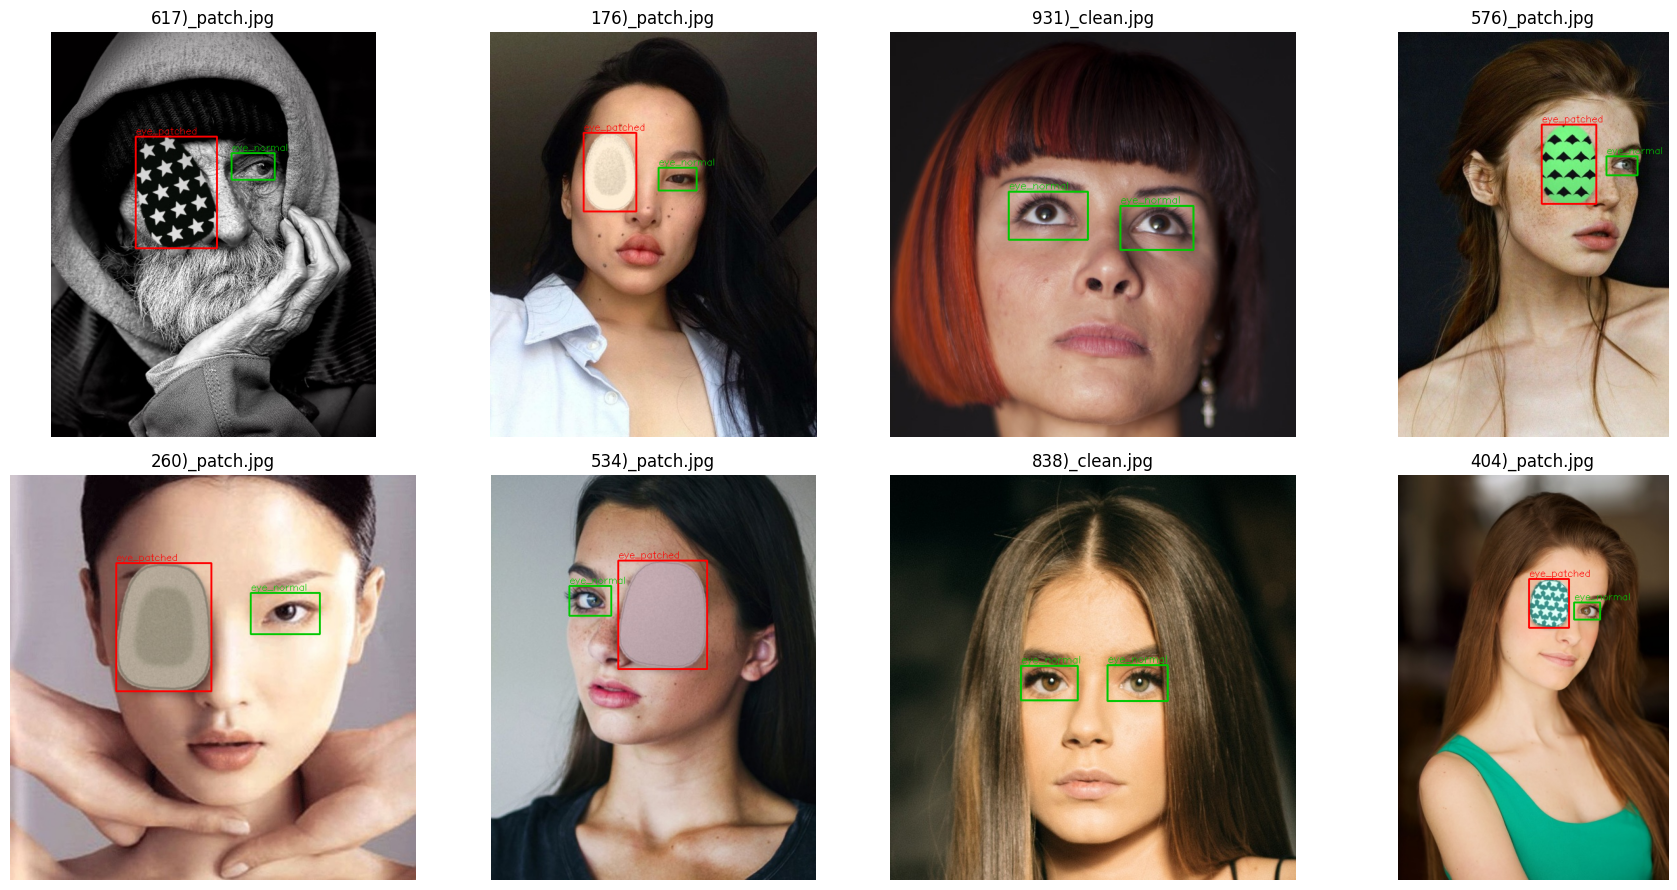

In [4]:
import cv2, random, glob, os
import matplotlib.pyplot as plt

DET = "/kaggle/working/yolo_det"
NAMES = ["eye_normal", "eye_patched"]
COLORS = [(0, 200, 0), (255, 0, 0)]      # RGB
imgs = sorted(glob.glob(f"{DET}/images/train/*_patch.jpg"))[:2000] + sorted(glob.glob(f"{DET}/images/train/*_clean.jpg"))[:2000]
sample = random.sample(imgs, min(8, len(imgs)))

fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for ax, p in zip(axs.ravel(), sample):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    lab = p.replace("/images/", "/labels/").replace(".jpg", ".txt")
    for line in open(lab).read().strip().splitlines():
        c, cx, cy, bw, bh = line.split(); c = int(c); cx, cy, bw, bh = map(float, (cx, cy, bw, bh))
        x1, y1 = int((cx - bw/2) * w), int((cy - bh/2) * h)
        x2, y2 = int((cx + bw/2) * w), int((cy + bh/2) * h)
        cv2.rectangle(im, (x1, y1), (x2, y2), COLORS[c], 2)
        cv2.putText(im, NAMES[c], (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, COLORS[c], 1)
    ax.imshow(im); ax.set_title(os.path.basename(p)[-14:]); ax.axis("off")
plt.tight_layout(); plt.show()

In [5]:
import pandas as pd
meta = pd.read_csv("/kaggle/working/meta.csv")
print(meta.groupby("split").size())
print(meta.covered_eye.value_counts())

split
test      701
train    5618
val       709
dtype: int64
covered_eye
right    3524
left     3504
Name: count, dtype: int64


In [7]:
from ultralytics import YOLO

det_model = YOLO("yolo11n.pt")
det_results = det_model.train(
    data="/kaggle/working/yolo_det/data.yaml",
    epochs=50,
    imgsz=640,
    batch=64,
    device=0,
    workers=2,
    patience=15,
    fliplr=0.5,          # flip is safe: classes are patched/normal, not left/right
    project="/kaggle/working/runs",
    name="patch_det",
    exist_ok=True,
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_det/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=patch_det, nbs=64, nms=None, opset=None, optimize=Fals

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      8.29G     0.7376     0.4662      1.029        113        640: 100% ━━━━━━━━━━━━ 176/176 2.1it/s 1:250.4sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.6it/s 7.5s0.6s
                   all       1418       2832      0.976      0.963      0.984      0.834

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      8.29G     0.7298     0.4473      1.024        136        640: 100% ━━━━━━━━━━━━ 176/176 2.1it/s 1:250.4sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.6it/s 7.3s0.6s
                   all       1418       2832       0.93      0.907       0.97      0.835

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      8.29G     0.7033     0.4169       1.01        113        640: 100% ━━━━━━━━━━━━ 176/176 2.1it/s 1:250.4sss
                 Class     Ima

In [9]:
best_det = "/kaggle/working/runs/patch_det/weights/best.pt"
det_model = YOLO(best_det)
m = det_model.val(data="/kaggle/working/yolo_det/data.yaml", split="test", imgsz=640, device=0)
print(f"all classes: precision={m.box.mp:.3f}  recall={m.box.mr:.3f}  mAP50={m.box.map50:.3f}  mAP50-95={m.box.map:.3f}")
for i, c in enumerate(m.box.ap_class_index):
    print(f"  {det_model.names[int(c)]:12s} AP50={m.box.ap50[i]:.3f}  AP50-95={m.box.ap[i]:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1374.1±403.6 MB/s, size: 85.3 KB)
val: Scanning /kaggle/working/yolo_det/labels/test.cache... 1402 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1402/1402 235.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 88/88 7.5it/s 11.7s0.1s
                   all       1402       2802      0.994      0.998      0.994      0.953
            eye_normal       1402       2101       0.99      0.998      0.993      0.914
           eye_patched        701        701      0.999      0.999      0.995      0.992
Speed: 0.8ms preprocess, 3.5ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2
all classes: precision=0.994  recall=0.998  mAP50=0.994  mAP50-95=0.953
  

In [10]:
cls_model = YOLO("yolo11n-cls.pt")
cls_results = cls_model.train(
    data="/kaggle/working/yolo_cls",
    epochs=50,
    imgsz=224,
    batch=64,
    device=0,
    workers=2,
    patience=10,
    project="/kaggle/working/runs",
    name="patch_cls",
    exist_ok=True,
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_cls, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=patch_cls, nbs=64, nms=None, opset=None, optimize=False, opt

In [11]:
best_cls = "/kaggle/working/runs/patch_cls/weights/best.pt"
cls_model = YOLO(best_cls)
m = cls_model.val(data="/kaggle/working/yolo_cls", split="test", imgsz=224, device=0)
print(f"top1 accuracy = {m.top1:.4f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: /kaggle/working/yolo_cls/train... found 11236 images in 2/2 classes ✅ 
val: /kaggle/working/yolo_cls/val... found 1418 images in 2/2 classes ✅ 
test: /kaggle/working/yolo_cls/test... found 1402 images in 2/2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1672.8±624.2 MB/s, size: 87.4 KB)
test: Scanning /kaggle/working/yolo_cls/test... 1402 images, 0 corrupt: 100% ━━━━━━━━━━━━ 1402/1402 2.2Kit/s 0.6s0.0s
test: New cache created: /kaggle/working/yolo_cls/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 88/88 17.6it/s 5.0s0.0s
                   all      0.996          1
Speed: 0.1ms preprocess, 1.6ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /kaggle/working/runs/classify/val
top1 accuracy = 0.9957


In [12]:
# confusion matrix + per-class report on the test set
import glob, numpy as np
from sklearn.metrics import classification_report, confusion_matrix

names = cls_model.names                       # {0: 'no_patch', 1: 'with_patch'}
y_true, y_pred = [], []
for cid, cname in names.items():
    files = glob.glob(f"/kaggle/working/yolo_cls/test/{cname}/*.jpg")
    for i in range(0, len(files), 64):
        for r in cls_model.predict(files[i:i+64], imgsz=224, device=0, verbose=False):
            y_pred.append(int(r.probs.top1)); y_true.append(cid)

print(classification_report(y_true, y_pred, target_names=[names[i] for i in sorted(names)], digits=4))
print(confusion_matrix(y_true, y_pred))

              precision    recall  f1-score   support

    no_patch     0.9943    0.9971    0.9957       701
  with_patch     0.9971    0.9943    0.9957       701

    accuracy                         0.9957      1402
   macro avg     0.9957    0.9957    0.9957      1402
weighted avg     0.9957    0.9957    0.9957      1402

[[699   2]
 [  4 697]]


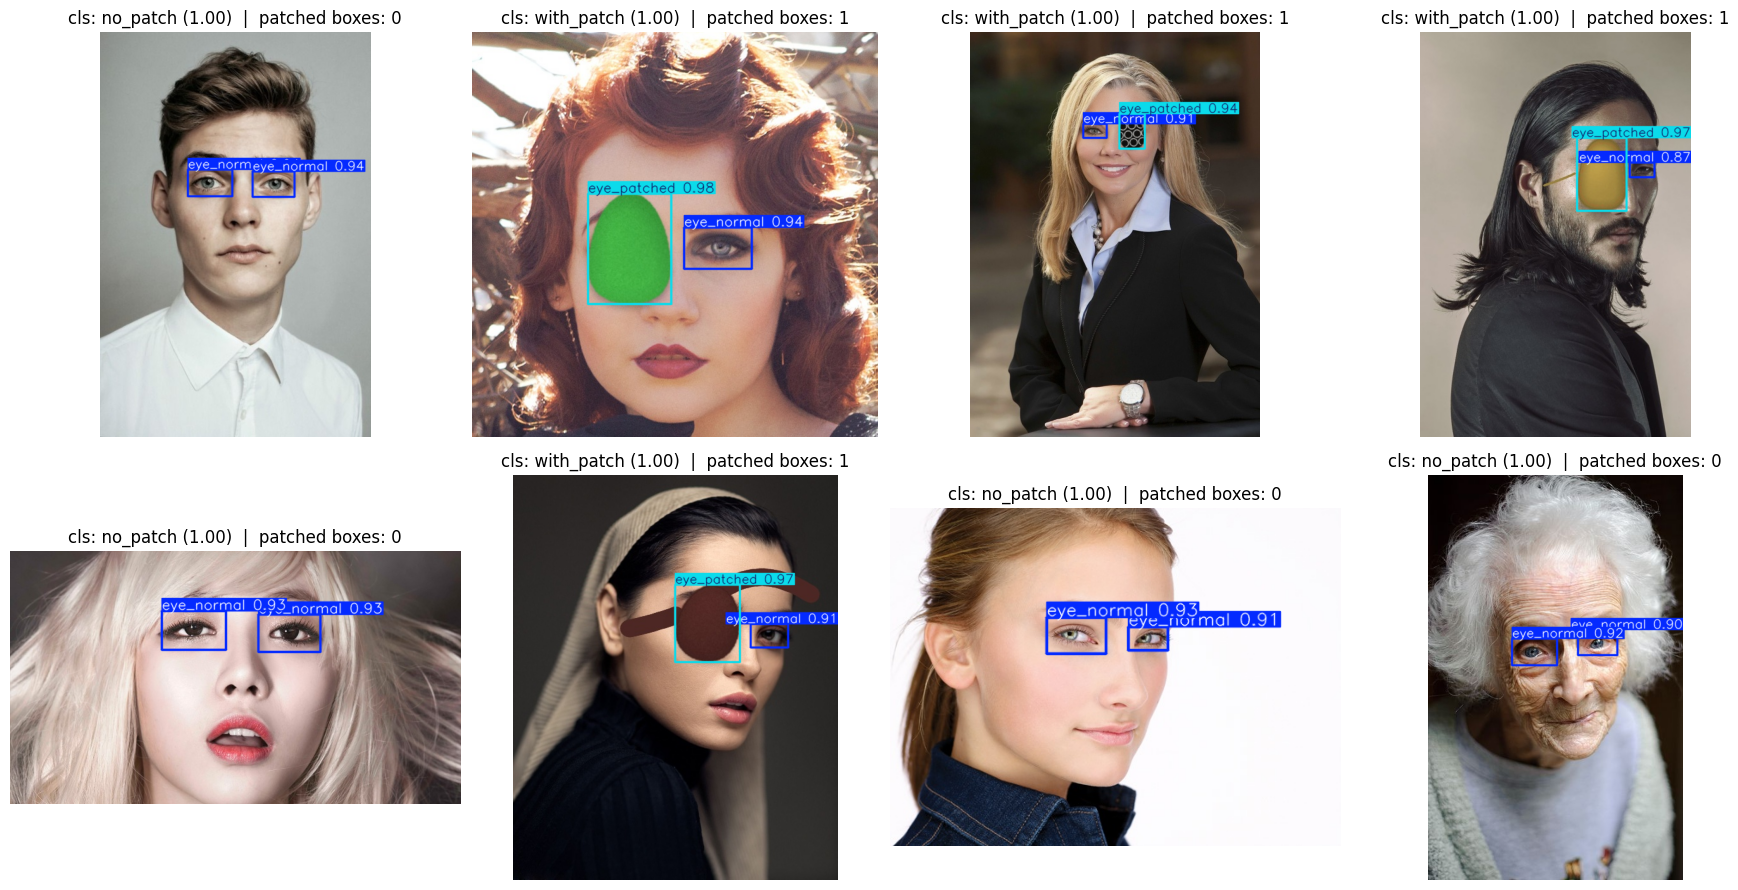

In [13]:
import random, glob, cv2, matplotlib.pyplot as plt

test_imgs = glob.glob("/kaggle/working/yolo_det/images/test/*.jpg")
sample = random.sample(test_imgs, min(8, len(test_imgs)))

fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for ax, p in zip(axs.ravel(), sample):
    det = det_model.predict(p, imgsz=640, conf=0.25, device=0, verbose=False)[0]
    cls = cls_model.predict(p, imgsz=224, device=0, verbose=False)[0]
    ax.imshow(cv2.cvtColor(det.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f"cls: {cls.names[int(cls.probs.top1)]} ({float(cls.probs.top1conf):.2f})  |  patched boxes: {int((det.boxes.cls == 1).sum())}")
    ax.axis("off")
plt.tight_layout(); plt.show()

In [14]:
from sklearn.metrics import accuracy_score

def det_says_patch(path, thr=0.4):
    r = det_model.predict(path, imgsz=640, conf=thr, device=0, verbose=False)[0]
    return int((r.boxes.cls == 1).any().item())   # class 1 = eye_patched

yt, yp = [], []
for cid, cname in {0: "no_patch", 1: "with_patch"}.items():
    for p in glob.glob(f"/kaggle/working/yolo_cls/test/{cname}/*.jpg"):
        yt.append(cid); yp.append(det_says_patch(p))
print("detector-as-classifier accuracy:", accuracy_score(yt, yp))
print(confusion_matrix(yt, yp))

detector-as-classifier accuracy: 0.9992867332382311
[[701   0]
 [  1 700]]


In [15]:
import shutil
shutil.copy(best_det, "/kaggle/working/patch_detector.pt")
shutil.copy(best_cls, "/kaggle/working/patch_classifier.pt")
 optional ONNX export:
 det_model.export(format="onnx", imgsz=640)
 cls_model.export(format="onnx", imgsz=224)
print("saved: patch_detector.pt , patch_classifier.pt")

IndentationError: unexpected indent (356308073.py, line 4)